In [48]:
import os
import cv2
import numpy as np
from datetime import datetime

from itertools import cycle

import seaborn as sns
import matplotlib.pyplot as plt


from tensorflow import keras
from keras.optimizers import Adam
from keras.models import load_model
from keras.models import Sequential

from keras.preprocessing.image import ImageDataGenerator
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense,Dropout,BatchNormalization

from keras.callbacks import ModelCheckpoint, EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [53]:
# Constants
image_height = 208
image_width = 176
batch_size = 64
epochs = 10
num_classes = 4

# # Data Generators with Image Augmentation
# train_datagen = ImageDataGenerator(
#     rescale=1./255,
#     rotation_range=20,
#     width_shift_range=0.2,
#     height_shift_range=0.2,
#     shear_range=0.2,
#     zoom_range=0.2,
#     horizontal_flip=True
# )

# test_datagen = ImageDataGenerator(rescale=1./255)

# # Read traing images
# train_generator = train_datagen.flow_from_directory(
#     '/content/drive/MyDrive/Colab Notebooks/data/input/Alzheimer_s Dataset/train',
#     target_size=(image_height, image_width),
#     batch_size=batch_size,
#     class_mode='categorical'
# )

# # Read test images
# test_generator = test_datagen.flow_from_directory(
#     '/content/drive/MyDrive/Colab Notebooks/data/input/Alzheimer_s Dataset/test',
#     target_size=(image_height, image_width),
#     batch_size=batch_size,
#     class_mode='categorical'
# )

In [88]:
test_percentage = 0.2  # Adjust the test percentage as needed

# Data Generator with Image Augmentation
datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=test_percentage  # Add validation split for test set
)

# Read images
generator = datagen.flow_from_directory(
    '/content/drive/MyDrive/Colab Notebooks/data/input/Alzheimer_s Dataset/train',
    target_size=(image_height, image_width),
    batch_size=batch_size,
    class_mode='categorical',
    subset='training'  # This generator will contain the training data
)

# Split data from the generator into train and test sets
train_data, test_data = train_test_split(generator, test_size=0.2)

Found 4098 images belonging to 4 classes.


In [ ]:
# Constants
# num_classes = 4
# class_names = ['MildDemented', 'ModerateDemented', 'NonDemented', 'VeryMildDemented']

# # Visualizing a single image from each class
# fig, axes = plt.subplots(1, num_classes, figsize=(15, 5))

# for i, class_name in enumerate(class_names):
#     class_directory = f'/content/drive/MyDrive/Colab Notebooks/data/input/Alzheimer_s Dataset/test/{class_name}/'
#     class_files = os.listdir(class_directory)
#     sample_image_path = os.path.join(class_directory, class_files[0])

#     sample_image = plt.imread(sample_image_path)
#     axes[i].imshow(sample_image,cmap='gray')
#     axes[i].set_title(class_name)
#     axes[i].axis('off')

# plt.tight_layout()
# plt.show()

# Fetch a batch of images and labels from test_data generator
for batch in test_data:
    sample_images, sample_labels = batch
    break  # Take the first batch for visualization

# Initialize dictionary to store one image per class
unique_classes = np.unique(np.argmax(sample_labels, axis=1))  # Get unique classes
images_per_class = {class_idx: None for class_idx in unique_classes}
print(unique_classes)

# Select one image per class for display
for i, label in enumerate(np.argmax(sample_labels, axis=1)):
    class_idx = int(label)
    if images_per_class[class_idx] is None:
        images_per_class[class_idx] = sample_images[i]

# Display one image for each class
num_classes_to_display = len(unique_classes)
plt.figure(figsize=(15, 5))

for i, class_idx in enumerate(unique_classes):
    plt.subplot(1, num_classes_to_display, i + 1)
    plt.imshow(images_per_class[class_idx])
    plt.title(f"Class: {list(unique_classes.keys())[class_idx]}")
    plt.axis('off')

plt.tight_layout()
plt.show()



In [90]:
# CNN 2D Model
model = Sequential()
model.add(Conv2D(16, (3, 3), activation='relu', input_shape=(image_height, image_width, 3)))
model.add(BatchNormalization())
model.add(MaxPooling2D((2, 2)))

model.add(Conv2D(32, (3, 3), activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D((2, 2)))

model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D((2, 2)))

model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D((2, 2)))

model.add(Conv2D(256, (3, 3), activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D((2, 2)))

model.add(Flatten())
model.add(Dense(256, activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(num_classes, activation='softmax'))

optimizer = Adam(learning_rate=0.00001)  # Adjust learning rate

# Compile the model
model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

# Get current timestamp
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

# Define the model checkpoint filename with timestamp
model_checkpoint_filename = '/content/drive/MyDrive/Colab Notebooks/data/output/model/alzheimers_best_model_{}.h5'.format(timestamp)

# Callbacks - ModelCheckpoint and EarlyStopping
checkpoint = ModelCheckpoint(model_checkpoint_filename, monitor='val_accuracy', save_best_only=True, mode='max', verbose=1)
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Model Training
# history = model.fit(
#     train_generator,
#     steps_per_epoch=train_generator.samples // batch_size,
#     epochs=epochs,
#     validation_data=test_generator,
#     validation_steps=test_generator.samples // batch_size,
#     callbacks=[checkpoint, early_stopping]
# )

# Model Training
history = model.fit(
                   train_data,
                    epochs=epochs,
                    steps_per_epoch=len(train_data),  # Number of batches per epoch
                    validation_data=test_data,
                    validation_steps=len(test_data),  # Number of validation batches
                    callbacks=[checkpoint, early_stopping]
                )

ValueError: ignored

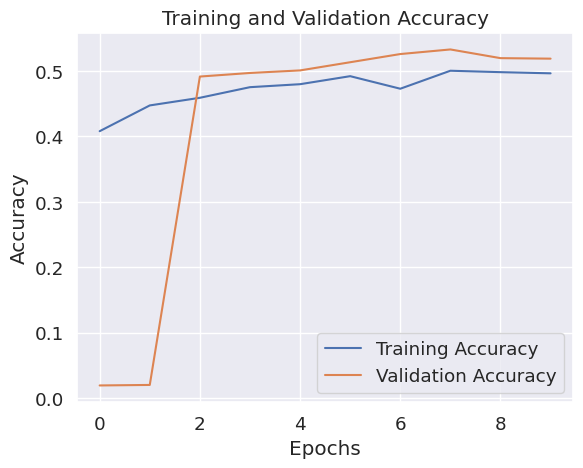

In [86]:
# Plot Training & Testing Accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

1/1 [==============================] - 0s 18ms/step


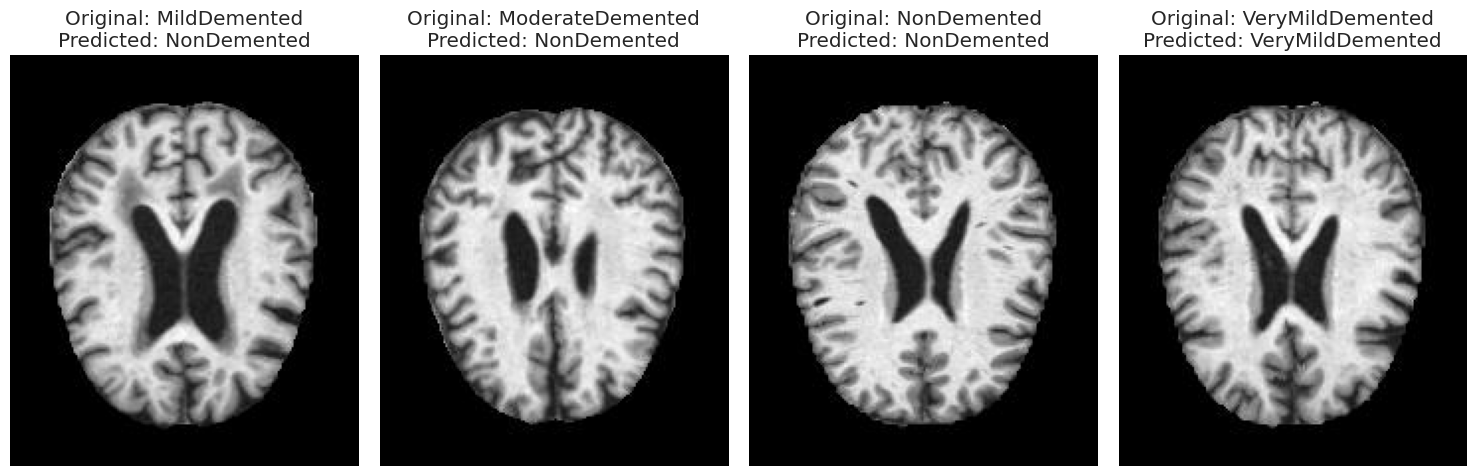

In [44]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from keras.models import load_model

# Load the saved model
loaded_model = load_model(model_checkpoint_filename)

# Sample image directory
sample_image_dir = '/content/drive/MyDrive/Colab Notebooks/data/input/Alzheimer_s Dataset/test/'

# Fetch class names from the directory
class_names = [folder for folder in os.listdir(sample_image_dir) if os.path.isdir(os.path.join(sample_image_dir, folder))]

# Image dimensions and number of images to display per class
image_height, image_width = 208, 176
num_images_to_display = 1

# Initialize lists to store predictions and corresponding images
predictions = []
images = []

# Process and predict for sample images
for class_name in class_names:
    class_directory = os.path.join(sample_image_dir, class_name)
    class_files = os.listdir(class_directory)
    for i in range(num_images_to_display):
        sample_image_path = os.path.join(class_directory, class_files[i])

        img = cv2.imread(sample_image_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (image_width, image_height))
        img = np.expand_dims(img, axis=0)
        img = img.astype('float32') / 255.0

        # Predict for the single image
        prediction = loaded_model.predict(img)[0]
        predicted_class_index = np.argmax(prediction)
        predicted_class_label = class_names[predicted_class_index]

        predictions.append((class_name, predicted_class_label))
        images.append(img.squeeze())  # Store processed images for display

# Display the images with original and predicted classes in a single row
plt.figure(figsize=(15, 5))

for i, (img, (original_class_label, predicted_class_label)) in enumerate(zip(images, predictions)):
    plt.subplot(1, len(images), i + 1)
    plt.imshow(img)
    plt.title(f"Original: {original_class_label}\nPredicted: {predicted_class_label}")
    plt.axis('off')

plt.tight_layout()
plt.show()


In [45]:
# Make predictions

predictions = loaded_model.predict(test_generator)
predicted_classes = np.argmax(predictions, axis=1)
true_classes = test_generator.classes

21/21 [==============================] - 3s 121ms/step


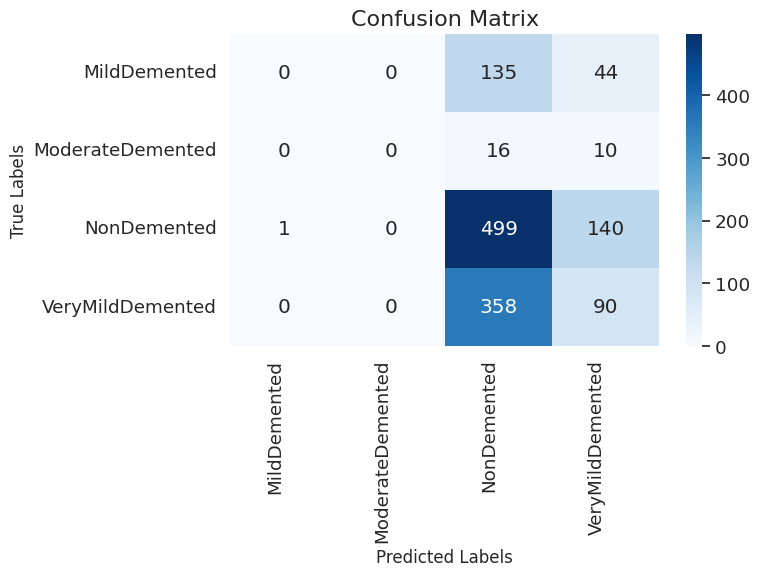

In [46]:
# Compute confusion matrix
cm = confusion_matrix(true_classes, predicted_classes)

class_names = ['MildDemented', 'ModerateDemented', 'NonDemented', 'VeryMildDemented']

# Create a heatmap using seaborn
plt.figure(figsize=(8, 6))
sns.set(font_scale=1.2)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix', fontsize=16)
plt.xlabel('Predicted Labels', fontsize=12)
plt.ylabel('True Labels', fontsize=12)
plt.xticks(rotation=90, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [47]:
# Calculate evaluation metrics
accuracy = accuracy_score(true_classes, predicted_classes)
precision = precision_score(true_classes, predicted_classes, average='micro')
recall = recall_score(true_classes, predicted_classes, average='micro')
f1 = f1_score(true_classes, predicted_classes, average='micro')
conf_matrix = confusion_matrix(true_classes, predicted_classes)

# Display the metrics
print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {f1}")

Accuracy: 0.45552977571539055
Precision: 0.45552977571539055
Recall: 0.45552977571539055
F1 Score: 0.45552977571539055
